In [1]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
print(device)

cpu


In [2]:
PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3
MAX_LEN = 50
BATCH_SIZE=64
EMBEDDING_DIM=64
HIDDEN_DIM=128
LEARNING_RATE=0.001
EPOCHS=10
TEACHER_FORCING_RATIO=0.5
CLIP_MAX_NORM=1.0

In [3]:
import json
def load_jsonl(path):
    df = {"src": [], "tgt": [], "n_clauses": [], "length_bucket": []}
    with open(path, "r") as f:
        lines = f.readlines()
        for line in lines:
            obj = json.loads(line)
            df['src'].append(obj['src'])
            df['tgt'].append(obj['tgt'])
            df['n_clauses'].append(obj['n_clauses'])
            df['length_bucket'].append(obj['length_bucket'])
    return df

In [4]:
df_train = pd.DataFrame(load_jsonl("train.jsonl"))
df_test = pd.DataFrame(load_jsonl("test.jsonl"))
df_val = pd.DataFrame(load_jsonl("val.jsonl"))
len(df_train), len(df_val), len(df_test)

(6000, 800, 800)

In [5]:
df_train.head()

,src,tgt,n_clauses,length_bucket
0,the blue cat throws the blue lamp and the quie...,bigai mouex smaai draol chaun yol bigai lamex ...,3,medium
1,the quiet wizard chases the blue cloud,bluai cloex quiai wizol chaun,1,short
2,the blue bear watches the young flower and the...,braai casex bluai kinol lovun yol oldai casex ...,3,medium
3,the brave queen carries the swift apple,swiai appex braai queol carun,1,short
4,the quiet cat follows the big lamp,bigai lamex quiai catol folun,1,short


In [6]:
df_train['length_bucket'] = df_train['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})
df_val['length_bucket'] = df_val['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})
df_test['length_bucket'] = df_test['length_bucket'].map({'short': 0, 'medium': 1, 'long': 2})

In [7]:
df_train['length_bucket'].value_counts()

length_bucket
1    2710
0    1802
2    1488
Name: count, dtype: int64

In [8]:
from collections import Counter
def preprocess(text):
    return text.lower().split()
class Vocab:
    def __init__(self, texts):
        c = Counter()
        for t in texts:
            c.update(preprocess(t))
        self.word2idx = {"<pad>": PAD_IDX, "<sos>": SOS_IDX, "<eos>": EOS_IDX, "<unk>": UNK_IDX}
        count = len(self.word2idx)
        self.idx2word = {PAD_IDX: "<pad>", SOS_IDX: "<sos>", EOS_IDX: "<eos>", UNK_IDX: "<unk>"}
        for word, _ in sorted(c.items(), key=lambda item: (-item[1], item[0])):
            self.word2idx[word] = count
            self.idx2word[count] = word
            count += 1
    def __len__(self):
        return len(self.word2idx)
    def encode(self, text):
        return [self.word2idx.get(t, UNK_IDX) for t in preprocess(text)]
    def decode(self, ids):
        out = []
        for i in ids:
            tok = self.idx2word[int(i)]
            if tok == "<eos>":
                break
            if tok not in ("<pad>", "<sos>"):
                out.append(tok)
        return " ".join(out)

In [9]:
src_vocab = Vocab(df_train['src'].values)
tgt_vocab = Vocab(df_train['tgt'].values)
len(src_vocab), len(tgt_vocab)

(50, 49)

In [10]:
class TranlationDataset(torch.utils.data.Dataset):
    def __init__(self, frame, src_vocab, tgt_vocab):
        # print("init")
        self.frame = frame.reset_index(drop=True)
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab
    def __len__(self):
        # print("len")
        return len(self.frame)
    def __getitem__(self, index):
        # print("getitem")
        r = self.frame.iloc[index]
        src_list = [self.src_vocab.word2idx["<sos>"]] + self.src_vocab.encode(r['src'])[:MAX_LEN-2] + [self.src_vocab.word2idx["<eos>"]]
        # src_len = len(src_list)
        # src_list += [self.src_vocab.word2idx["<pad>"]] * (MAX_LEN - src_len)
        src_mask = [1] * len(src_list) + [0] * (MAX_LEN - len(src_list))
        src_mask = torch.tensor(src_mask, dtype=torch.long)
        src_list.extend([PAD_IDX] * (MAX_LEN - len(src_list)))
        src = torch.tensor(
            src_list,
            dtype=torch.long
        )
        tgt_list = [self.tgt_vocab.word2idx["<sos>"]] + self.tgt_vocab.encode(r['tgt'])[:MAX_LEN-2] + [self.tgt_vocab.word2idx["<eos>"]]
        # tgt_len = len(tgt_list)
        # tgt_list += [self.tgt_vocab.word2idx["<pad>"]] * (MAX_LEN - tgt_len)
        tgt_mask = [1] * len(tgt_list) + [0] * (MAX_LEN - len(tgt_list))
        tgt_mask = torch.tensor(tgt_mask, dtype=torch.long)
        tgt_list.extend([PAD_IDX] * (MAX_LEN - len(tgt_list)))
        tgt = torch.tensor(
            tgt_list,
            dtype=torch.long
        )
        # print(src)
        # print(tgt)
        length_bucket = torch.tensor(r['length_bucket'], dtype=torch.long)
        return src, tgt, length_bucket, src_mask, tgt_mask

In [11]:
train_data = TranlationDataset(df_train, src_vocab, tgt_vocab)

In [12]:
len(train_data)

6000

In [13]:
x1 = train_data.__getitem__(0)
x2 = train_data.__getitem__(1)
print(x1[0].shape)
torch.stack((x1[0], x2[0])).shape

torch.Size([50])


torch.Size([2, 50])

In [14]:
x = [0, 1, 3, 2]
random.shuffle(x)
x

[3, 1, 2, 0]

In [15]:
class MyDataloader:
    def __init__(self, data, batch_size=BATCH_SIZE, device=device):
        self.pos = 0
        self.data = data
        self.batch_size = batch_size
        self.ids = list(range(len(data)))
        random.shuffle(self.ids)
        self.device = device
    def __len__(self):
        return len(self.data) // self.batch_size
    def __iter__(self):
        for _ in range(len(self)):
            srcs = []; tgts = []; length_buckets = []; src_masks = []; tgt_masks = []
            for i in range(self.pos, self.pos+self.batch_size):
                src, tgt, length_bucket, src_mask, tgt_mask = self.data.__getitem__(self.ids[i])
                srcs.append(src); tgts.append(tgt); length_buckets.append(length_bucket)
                src_masks.append(src_mask); tgt_masks.append(tgt_mask)
            srcs = torch.stack(srcs).to(self.device)
            tgts = torch.stack(tgts).to(self.device)
            length_buckets = torch.stack(length_buckets).to(self.device)
            src_masks = torch.stack(src_masks).to(self.device)
            tgt_masks = torch.stack(tgt_masks).to(self.device)
            batch_tensors = (srcs, tgts, length_buckets, src_masks, tgt_masks)
            self.pos = (self.pos + self.batch_size) % self.batch_size
            yield batch_tensors
    def get_batches(self):
        return next(self.__iter__())

In [16]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [17]:
def lstm_cell_forward(x_t, h_prev, c_prev, Wx, Wh, b):
    gates = x_t @ Wx + h_prev @ Wh + b
    # print(gates.shape)
    d = gates.shape[-1]
    d = d // 4
    i, f, g, o = gates[..., :d], gates[..., d:2*d], gates[..., 2*d:3*d], gates[..., 3*d:]
    # print(gates.shape)
    # print(i.shape)
    i = sigmoid(i)
    f = sigmoid(f)
    g = np.tanh(g)
    o = sigmoid(o)
    c_new = f * c_prev + i * g
    h_new = o * np.tanh(c_new)
    return h_new, c_new

In [18]:
x1 = np.random.rand(1, 4)
h_prev = np.random.rand(1, 4)
c_prev = np.random.rand(1, 4)
W = np.random.rand(4, 4 * 4)
b = np.random.rand(4 * 4)
h_new, c_new = lstm_cell_forward(x1, h_prev, c_prev, W, W, b)
h_new.shape, c_new.shape

((1, 4), (1, 4))

In [19]:
def calculate_parameters(input_dim, hidden_dim, cell="rnn"):
    if cell == "rnn":
        return input_dim * hidden_dim + hidden_dim * hidden_dim + 2 * hidden_dim
    elif cell == "gru":
        return input_dim * 3 * hidden_dim + hidden_dim * 3 * hidden_dim + 6 * hidden_dim
    else: # lstm
        """ FROM PYTORCH
        i = \sigma(W_{ii} x + b_{ii} + W_{hi} h + b_{hi}) \\
        f = \sigma(W_{if} x + b_{if} + W_{hf} h + b_{hf}) \\
        g = \tanh(W_{ig} x + b_{ig} + W_{hg} h + b_{hg}) \\
        o = \sigma(W_{io} x + b_{io} + W_{ho} h + b_{ho}) \\
        c' = f \odot c + i \odot g \\
        h' = o \odot \tanh(c') \\
        """
        return input_dim * 4 * hidden_dim + hidden_dim * 4 * hidden_dim + 8 * hidden_dim

In [20]:
calculate_parameters(EMBEDDING_DIM, HIDDEN_DIM, "rnn")

24832

In [21]:
calculate_parameters(EMBEDDING_DIM, HIDDEN_DIM, "gru")

74496

In [22]:
calculate_parameters(EMBEDDING_DIM, HIDDEN_DIM, "lstm")

99328

In [23]:
class EncoderGRU(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim):
        super().__init__()
        self.emb_dim = emb_dim
        self.hid_dim = hid_dim
        self.emb = nn.Embedding(input_dim, emb_dim, padding_idx=PAD_IDX)
        self.cell = nn.GRUCell(emb_dim, hid_dim)
    def forward(self, x, mask, h=None, return_history=False):
        x = self.emb(x)
        b, s, d = x.shape
        if h is None:
            h = torch.zeros(b, self.hid_dim, device=x.device, dtype=x.dtype)
        history = []
        for t in range(s):
            h_new = self.cell(x[:, t, :], h)
            m = mask[:, t].unsqueeze(1).to(x.dtype)
            h = m * h_new + (1-m) * h
            if return_history:
                history.append(h)
        if return_history:
            history = torch.stack(history, dim=1)
            return h, history
        return h

In [24]:
class DecoderGRU(nn.Module):
    def __init__(self, encoder, out_dim):
        super().__init__()
        self.encoder = encoder
        self.emb = nn.Embedding(out_dim, self.encoder.emb_dim, padding_idx=PAD_IDX)
        self.cell = nn.GRUCell(self.encoder.emb_dim, self.encoder.hid_dim)
        self.p = nn.Linear(self.encoder.hid_dim, self.encoder.emb_dim)
        self.proj = nn.Linear(self.encoder.emb_dim, out_dim, bias=False)
        self.proj.weight = self.emb.weight
    def forward(self, tgt, tgt_mask, src, src_mask, tf=TEACHER_FORCING_RATIO):
        tgt_emb = self.emb(tgt)
        # print(tgt_emb.shape)
        b, T, d = tgt_emb.shape
        h = self.encoder(src, src_mask)
        token = tgt_emb[:, 0, :]
        outputs = []
        for t in range(1, T):
            h_new = self.cell(token, h)
            m = tgt_mask[:, t].unsqueeze(1).to(tgt_emb.dtype)
            h = m * h_new + (1 - m) * h
            logits = self.proj(self.p(h))
            outputs.append(logits)
            if random.random() < tf:
                token = tgt_emb[:, t, :]
            else:
                pred = logits.argmax(dim=-1)
                token = self.emb(pred)
        return torch.stack(outputs, dim=1)

In [25]:
class EncoderLSTM(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim):
        super().__init__()
        self.emb_dim = emb_dim
        self.hid_dim = hid_dim
        self.emb = nn.Embedding(input_dim, emb_dim, padding_idx=PAD_IDX)
        self.cell = nn.LSTMCell(emb_dim, hid_dim)
    def forward(self, x, mask, h=None, c=None, return_history=False):
        x = self.emb(x)
        b, s, d = x.shape
        if h is None:
            h = torch.zeros(b, self.hid_dim, device=x.device, dtype=x.dtype)
            c = torch.zeros(b, self.hid_dim, device=x.device, dtype=x.dtype)
        h_history = []
        c_history = []
        for t in range(s):
            h_new, c_new  = self.cell(x[:, t, :], (h, c))
            m = mask[:, t].unsqueeze(1).to(x.dtype)
            h = m * h_new + (1-m) * h
            c = m * c_new + (1-m) * c
            if return_history:
                h_history.append(h)
                c_history.append(h)
        if return_history:
            h_history = torch.stack(h_history, dim=1)
            c_history = torch.stack(c_history, dim=1)
            return h,c, h_history, c_history
        return h, c

In [26]:
class DecoderLSTM(nn.Module):
    def __init__(self, encoder, out_dim):
        super().__init__()
        self.encoder = encoder
        self.emb = nn.Embedding(out_dim, self.encoder.emb_dim, padding_idx=PAD_IDX)
        self.cell = nn.LSTMCell(self.encoder.emb_dim, self.encoder.hid_dim)
        self.p = nn.Linear(self.encoder.hid_dim, self.encoder.emb_dim)
        self.proj = nn.Linear(self.encoder.emb_dim, out_dim, bias=False)
        self.proj.weight = self.emb.weight
    def forward(self, tgt, tgt_mask, src, src_mask, tf=TEACHER_FORCING_RATIO):
        tgt_emb = self.emb(tgt)
        b, T, d = tgt_emb.shape
        h, c = self.encoder(src, src_mask)
        token = tgt_emb[:, 0, :]
        outputs = []
        for t in range(1, T):
            h_new, c_new = self.cell(token, (h, c))
            m = tgt_mask[:, t].unsqueeze(1).to(tgt_emb.dtype)
            h = m * h_new + (1 - m) * h
            c = m * c_new + (1 - m) * c
            logits = self.proj(self.p(h))
            outputs.append(logits)
            if random.random() < tf:
                token = tgt_emb[:, t, :]
            else:
                pred = logits.argmax(dim=-1)
                token = self.emb(pred)
        return torch.stack(outputs, dim=1)

In [27]:
class GatedSeq2Seq:
    def __init__(self, src_vocab_size, tgt_vocab_size, cell_type="gru"):
        self.cell_type =  cell_type
        if cell_type == "gru":
            self.encoder = EncoderGRU(src_vocab_size, EMBEDDING_DIM, HIDDEN_DIM)
            self.decoder = DecoderGRU(self.encoder, tgt_vocab_size)
        else: # lstm
            self.encoder = EncoderLSTM(src_vocab_size, EMBEDDING_DIM, HIDDEN_DIM)
            self.decoder = DecoderLSTM(self.encoder, tgt_vocab_size)

In [28]:
from tqdm import tqdm
import time
def train_epoch(model, loader, optimizer, clip_grad=False):
    model.train()
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    for srcs, tgts, length_buckets, src_masks, tgt_masks in tqdm(loader, desc="Calculating train loss"):
        output = model(tgts, tgt_masks, srcs, src_masks)
        true_label = tgts[:, 1:]
        output = output.reshape(-1, output.shape[-1])
        true_label = true_label.reshape(-1)
        loss = criterion(output, true_label.long())
        total_loss += loss.item()
        loss.backward()
        if clip_grad:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_MAX_NORM)
        optimizer.step()
        optimizer.zero_grad()
    total_loss /= max(1, len(loader))
    return total_loss

In [29]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    start_time = time.time()
    for srcs, tgts, length_buckets, src_masks, tgt_masks in tqdm(loader, desc="Calculating val loss"):
        output = model(tgts, tgt_masks, srcs, src_masks)
        true_label = tgts[:, 1:]
        output = output.reshape(-1, output.shape[-1])
        true_label = true_label.reshape(-1)
        loss = criterion(output, true_label.long())
        total_loss += loss.item()
    end_time = time.time()
    total_loss /= max(1, len(loader))
    avg_latency = (end_time - start_time) / max(1, len(loader))
    return total_loss, avg_latency

Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 67.04it/s]


Train loss: 2.0209, Val loss: 2.7072, latency: 15.0(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 33.87it/s]


Train loss: 0.1588, Val loss: 5.2886, latency: 29.6(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 67.86it/s]


...

Train loss: 0.0006, Val loss: 7.4057, latency: 15.2(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 65.94it/s]


Train loss: 0.0004, Val loss: 7.5989, latency: 15.3(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 34.64it/s]


Train loss: 0.0004, Val loss: 7.6992, latency: 29.0(ms)
Total train time: 57.2596(s)


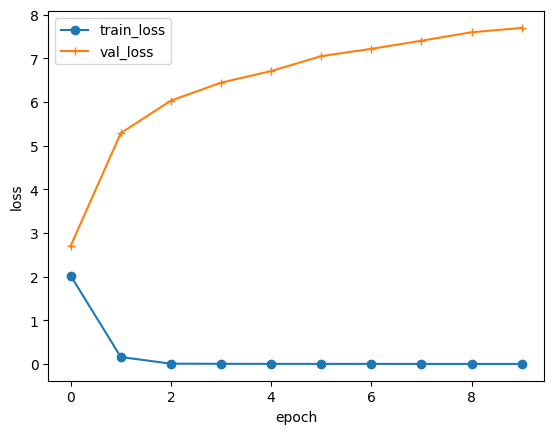

In [30]:
NUM_EPOCHS = 10
task = GatedSeq2Seq(len(src_vocab), len(tgt_vocab), cell_type="gru")
model_gru = task.decoder
model_gru.to(device)
optimizer = torch.optim.Adam(model_gru.parameters(), lr=LEARNING_RATE)
train_loader = MyDataloader(TranlationDataset(df_train, src_vocab, tgt_vocab))
val_loader = MyDataloader(TranlationDataset(df_val, src_vocab, tgt_vocab))
train_losses = []
val_losses = []
total_train_time = 0
for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss = train_epoch(model_gru, train_loader, optimizer, clip_grad=True)
    end = time.time()
    total_train_time += (end - start)
    val_loss, avg_latency = evaluate(model_gru, val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Train loss: {train_loss:.4f}, Val loss: {val_loss:.4f}, latency: {avg_latency * 1000:.1f}(ms)")
print(f"Total train time: {total_train_time:.4f}(s)")
from matplotlib import pyplot as plt
plt.plot(train_losses, marker='o', label='train_loss')
plt.plot(val_losses, marker='+', label='val_loss')
plt.legend()
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 51.38it/s]


Train loss: 1.9229, Val loss: 3.5415, latency: 19.6(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 26.63it/s]


Train loss: 0.0301, Val loss: 5.5048, latency: 37.7(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 26.04it/s]


...

Train loss: 0.0004, Val loss: 6.7213, latency: 38.6(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 50.91it/s]


Train loss: 0.0003, Val loss: 6.8807, latency: 19.8(ms)


Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 26.17it/s]

Train loss: 0.0002, Val loss: 7.0919, latency: 38.3(ms)
Total train time: 67.0121(s)


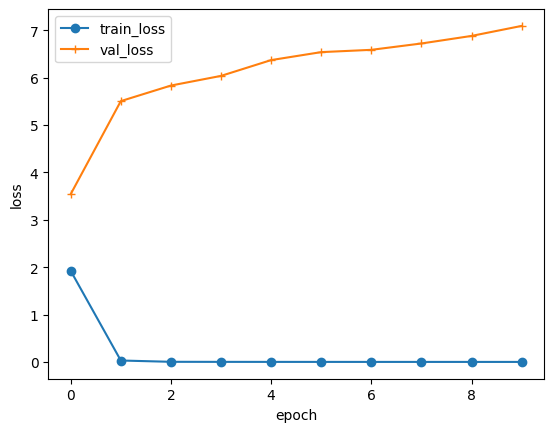

In [31]:
NUM_EPOCHS = 10
task = GatedSeq2Seq(len(src_vocab), len(tgt_vocab), cell_type="lstm")
model_lstm = task.decoder
model_lstm.to(device)
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE)
train_loader = MyDataloader(TranlationDataset(df_train, src_vocab, tgt_vocab))
val_loader = MyDataloader(TranlationDataset(df_val, src_vocab, tgt_vocab))
train_losses = []
val_losses = []
total_train_time = 0
for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss = train_epoch(model_lstm, train_loader, optimizer, clip_grad=True)
    end = time.time()
    total_train_time += (end - start)
    val_loss, avg_latency = evaluate(model_lstm, val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Train loss: {train_loss:.4f}, Val loss: {val_loss:.4f}, latency: {avg_latency * 1000:.1f}(ms)")
print(f"Total train time: {total_train_time:.4f}(s)")
from matplotlib import pyplot as plt
plt.plot(train_losses, marker='o', label='train_loss')
plt.plot(val_losses, marker='+', label='val_loss')
plt.legend()
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [32]:
@torch.no_grad()
def evaluate(model, loader, tf=0.5):
    model.eval()
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
    start_time = time.time()
    for srcs, tgts, length_buckets, src_masks, tgt_masks in tqdm(loader, desc="Calculating val loss"):
        output = model(tgts, tgt_masks, srcs, src_masks, tf=tf)
        true_label = tgts[:, 1:]
        output = output.reshape(-1, output.shape[-1])
        true_label = true_label.reshape(-1)
        loss = criterion(output, true_label.long())
        total_loss += loss.item()
    end_time = time.time()
    total_loss /= max(1, len(loader))
    avg_latency = (end_time - start_time) / max(1, len(loader))
    return total_loss, avg_latency

In [33]:
evaluate(model_gru, val_loader, tf=0.0)

Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 62.44it/s]


(8.062106132507324, 0.016147176424662273)

In [34]:
evaluate(model_gru, val_loader, tf=1.0)

Calculating val loss: 100%|██████████| 12/12 [00:00<00:00, 39.96it/s]


(8.243633270263672, 0.02514892816543579)

In [35]:
@torch.no_grad()
def greedy_decode(model, src, src_mask, max_len=MAX_LEN):
    model.eval()
    b = src.shape[0]
    h = model.encoder(src, src_mask)
    token_id = torch.full((b,), SOS_IDX, dtype=torch.long, device=src.device)
    token = model.emb(token_id)
    finished = torch.zeros(b, dtype=torch.bool, device=src.device)
    out_ids = torch.full((b, max_len), PAD_IDX, dtype=torch.long, device=src.device)
    for t in range(1, MAX_LEN):
        h = model.cell(token, h)[:1]
        logits = model.proj(model.p(h))
        preds = logits.argmax(dim=1)
        preds = torch.where(finished, torch.full_like(preds, PAD_IDX), preds)
        out_ids[:, t] = preds
        finished = finished | (preds == EOS_IDX)
        token = model.emb(preds)
        if finished.all():
            break
    return out_ids

In [ ]:
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
test_loader = MyDataloader(TranlationDataset(df_test, src_vocab, tgt_vocab))
model_gru.eval()
row = 0
with torch.no_grad():
    for srcs, tgts, length_buckets, src_masks, tgt_masks in tqdm(test_loader):
        pred_ids = greedy_decode(model_gru, srcs, src_masks).cpu()
        bsz = srcs.shape[0]
        for i in range(bsz):
            hyp_tokens = tgt_vocab.decode(pred_ids[i].tolist()).split()
            ref_tokens = preprocess(df_test.iloc[row]["tgt"])
            